# 01 — Data Pooling, Patient-ID Extraction, Duplicate Check & Patient-Level 5-Fold Split
Kermany (5,856 images, 3-class: NORMAL / BACTERIA / VIRUS) → one pool → patient-level `StratifiedGroupKFold`.

In [1]:
# ============================================================
# Imports & Config
# ============================================================
import re, hashlib, random, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

SPLIT_SEED = 42      # fixed split seed (training seeds vary later, split stays the same)
N_FOLDS    = 5
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

DATASET_DIR  = Path("/mnt/g/Research paper/Research paper/dataset of pneomunia/chest_xray")
PROJECT_ROOT = Path("/mnt/g/Research paper/Research paper/Pneumonia-MultiModel-XAI")
SPLITS_DIR   = PROJECT_ROOT / "splits"
RESULTS_DIR  = PROJECT_ROOT / "results"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SPLIT_SEED); np.random.seed(SPLIT_SEED)
print("Dataset exists:", DATASET_DIR.exists())

Dataset exists: True


In [2]:
# ============================================================
# 1. Pool all images (train + val + test) into one table
# ============================================================
records = []
for orig_split in ["train", "val", "test"]:
    for class_dir in sorted((DATASET_DIR / orig_split).iterdir()):
        if not class_dir.is_dir():
            continue
        for p in sorted(class_dir.iterdir()):
            if p.suffix.lower() not in IMAGE_EXTS:
                continue
            name = p.name.lower()
            if class_dir.name == "NORMAL":
                label = "NORMAL"
            elif "bacteria" in name:
                label = "BACTERIA"
            elif "virus" in name:
                label = "VIRUS"
            else:
                continue
            records.append({
                "image_path": str(p.relative_to(DATASET_DIR)),
                "filename": p.name,
                "original_split": orig_split,
                "label": label,
            })

df = pd.DataFrame(records)
print("Total images:", len(df))
print(df["label"].value_counts().sort_index().to_string())
assert len(df) == 5856, "Expected 5,856 Kermany images"

Total images: 5856
label
BACTERIA    2780
NORMAL      1583
VIRUS       1493


In [3]:
# ============================================================
# 2. Patient ID from filename
#    BACTERIA/VIRUS : person{ID}_{bacteria|virus}_{n}.jpeg
#    NORMAL         : IM-{ID}-{n}.jpeg  /  NORMAL2-IM-{ID}-{n}.jpeg
# ============================================================
RE_PERSON = re.compile(r"person(\d+)_(?:bacteria|virus)_\d+", re.I)
RE_NORMAL = re.compile(r"IM-(\d+)", re.I)

def extract_patient_id(filename, label):
    if label == "NORMAL":
        m = RE_NORMAL.search(filename)
        return f"NORMAL_IM{int(m.group(1)):04d}" if m else None
    m = RE_PERSON.search(filename)
    return f"{label}_P{int(m.group(1)):05d}" if m else None

df["patient_id"] = [extract_patient_id(f, l) for f, l in zip(df["filename"], df["label"])]

n_missing = df["patient_id"].isna().sum()
print("Filenames without patient ID:", n_missing)
if n_missing:
    display(df[df["patient_id"].isna()].head(20))
assert n_missing == 0, "Fix regex for the filenames above"

per_patient = df.groupby("patient_id").size()
print(f"Unique patients : {per_patient.shape[0]:,}")
print(f"Images/patient  : mean {per_patient.mean():.2f} | max {per_patient.max()}")
print(df.groupby("label")["patient_id"].nunique().to_string())

Filenames without patient ID: 0
Unique patients : 3,769
Images/patient  : mean 1.55 | max 30
label
BACTERIA    1437
NORMAL      1116
VIRUS       1216


In [4]:
# ============================================================
# 3. Integrity + hashes (MD5 = exact duplicate, dHash = near duplicate)
# ============================================================
def file_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def dhash64(img):
    g = img.convert("L").resize((9, 8), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return "".join("1" if b else "0" for b in bits)

md5s, dhs, widths, heights, corrupted = [], [], [], [], []
for rel in df["image_path"]:
    p = DATASET_DIR / rel
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            widths.append(im.size[0]); heights.append(im.size[1])
            dhs.append(dhash64(im))
        md5s.append(file_md5(p))
    except Exception:
        corrupted.append(rel); md5s.append(None); dhs.append(None)
        widths.append(None); heights.append(None)

df["md5"], df["dhash"], df["width"], df["height"] = md5s, dhs, widths, heights
print("Corrupted images:", len(corrupted))
assert len(corrupted) == 0

Corrupted images: 0


In [5]:
# ============================================================
# 4. Duplicate report
# ============================================================
dup_md5 = df[df.duplicated("md5", keep=False)]
dup_dh  = df[df.duplicated("dhash", keep=False)]
print(f"Exact duplicates (MD5)   : {dup_md5['md5'].nunique()} groups / {len(dup_md5)} images")
print(f"Near duplicates (dHash)  : {dup_dh['dhash'].nunique()} groups / {len(dup_dh)} images")

# duplicates whose labels disagree = label noise
lab_conflict = df.groupby("md5")["label"].nunique()
print("MD5 groups with conflicting labels:", int((lab_conflict > 1).sum()))

# duplicates already inside the same patient vs across patients
def across_patients(col):
    g = df.groupby(col)["patient_id"].nunique()
    return int((g > 1).sum())
print("MD5 groups spanning >1 patient   :", across_patients("md5"))
print("dHash groups spanning >1 patient :", across_patients("dhash"))

Exact duplicates (MD5)   : 30 groups / 62 images
Near duplicates (dHash)  : 478 groups / 1690 images
MD5 groups with conflicting labels: 0
MD5 groups spanning >1 patient   : 1
dHash groups spanning >1 patient : 451


In [6]:
# ============================================================
# 5. Leak-proof groups = patient ID  ∪  MD5  (union-find)
#    dHash is report-only (9x8 hash gives too many false matches on X-rays).
# ============================================================
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

for pid, md5, dh in zip(df["patient_id"], df["md5"], df["dhash"]):
    union("P:" + pid, "M:" + md5)

df["group_id"] = [find("P:" + pid) for pid in df["patient_id"]]
df["group_id"] = pd.factorize(df["group_id"])[0]

gsize = df.groupby("group_id").size()
print(f"Groups: {gsize.shape[0]:,} | largest group: {gsize.max()} images")
# a group mixing labels would break stratification -> inspect
mixed = df.groupby("group_id")["label"].nunique()
print("Groups with mixed labels:", int((mixed > 1).sum()))

Groups: 3,768 | largest group: 30 images
Groups with mixed labels: 0


In [7]:
# ============================================================
# 6. Patient-level StratifiedGroupKFold (5 folds)
#    fold k : test = fold k | val = fold (k+1)%5 | train = rest   (~60/20/20)
# ============================================================
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SPLIT_SEED)

df["test_fold"] = -1
for k, (_, te_idx) in enumerate(sgkf.split(df, df["label"], groups=df["group_id"])):
    df.loc[df.index[te_idx], "test_fold"] = k
assert (df["test_fold"] >= 0).all()

for k in range(N_FOLDS):
    val_fold = (k + 1) % N_FOLDS
    df[f"fold{k}"] = np.where(df["test_fold"] == k, "test",
                      np.where(df["test_fold"] == val_fold, "val", "train"))

summary = []
for k in range(N_FOLDS):
    for role in ["train", "val", "test"]:
        sub = df[df[f"fold{k}"] == role]
        row = {"fold": k, "role": role, "images": len(sub), "patients": sub["group_id"].nunique()}
        row.update(sub["label"].value_counts().to_dict())
        summary.append(row)
summary = pd.DataFrame(summary).fillna(0)
display(summary)

,fold,role,images,patients,BACTERIA,NORMAL,VIRUS
0,0,train,3513,2262,1668,950,895
1,0,val,1172,753,556,317,299
2,0,test,1171,753,556,316,299
3,1,train,3513,2261,1668,950,895
4,1,val,1171,754,556,316,299
5,1,test,1172,753,556,317,299
6,2,train,3514,2260,1668,950,896
7,2,val,1171,754,556,317,298
8,2,test,1171,754,556,316,299
9,3,train,3514,2260,1668,949,897


In [8]:
# ============================================================
# 7. Verification (must all pass)
# ============================================================
for k in range(N_FOLDS):
    g = {r: set(df.loc[df[f"fold{k}"] == r, "group_id"]) for r in ["train", "val", "test"]}
    assert not (g["train"] & g["val"]),  f"fold{k}: train/val group leak"
    assert not (g["train"] & g["test"]), f"fold{k}: train/test group leak"
    assert not (g["val"]   & g["test"]), f"fold{k}: val/test group leak"

    md = {r: set(df.loc[df[f"fold{k}"] == r, "md5"]) for r in ["train", "val", "test"]}
    assert not (md["train"] & md["test"]) and not (md["train"] & md["val"]) and not (md["val"] & md["test"]), \
        f"fold{k}: duplicate image across splits"

    pid = {r: set(df.loc[df[f"fold{k}"] == r, "patient_id"]) for r in ["train", "val", "test"]}
    assert not (pid["train"] & pid["test"]) and not (pid["train"] & pid["val"]) and not (pid["val"] & pid["test"]), \
        f"fold{k}: patient overlap"

assert df["test_fold"].value_counts().sum() == len(df)   # every image is test exactly once
print("✅ No patient / duplicate overlap across train-val-test in any fold.")
print("✅ Every image appears in test exactly once.")
print("\nTest-fold sizes:", df["test_fold"].value_counts().sort_index().tolist())

✅ No patient / duplicate overlap across train-val-test in any fold.
✅ Every image appears in test exactly once.

Test-fold sizes: [1171, 1172, 1171, 1171, 1171]


In [9]:
# ============================================================
# 8. Save split files
# ============================================================
cols = ["image_path", "filename", "label", "patient_id", "group_id", "md5", "dhash",
        "width", "height", "original_split", "test_fold"] + [f"fold{k}" for k in range(N_FOLDS)]
df[cols].to_csv(SPLITS_DIR / "kermany_patient_splits.csv", index=False)
summary.to_csv(SPLITS_DIR / "kermany_split_summary.csv", index=False)

# per-fold CSVs (train / val / test)
for k in range(N_FOLDS):
    for role in ["train", "val", "test"]:
        df.loc[df[f"fold{k}"] == role, ["image_path", "label", "patient_id"]] \
          .to_csv(SPLITS_DIR / f"fold{k}_{role}.csv", index=False)

print("Saved to:", SPLITS_DIR)
print(sorted(p.name for p in SPLITS_DIR.iterdir()))

Saved to: /mnt/g/Research paper/Research paper/Pneumonia-MultiModel-XAI/splits
['fold0_test.csv', 'fold0_train.csv', 'fold0_val.csv', 'fold1_test.csv', 'fold1_train.csv', 'fold1_val.csv', 'fold2_test.csv', 'fold2_train.csv', 'fold2_val.csv', 'fold3_test.csv', 'fold3_train.csv', 'fold3_val.csv', 'fold4_test.csv', 'fold4_train.csv', 'fold4_val.csv', 'kermany_patient_splits.csv', 'kermany_split_summary.csv']


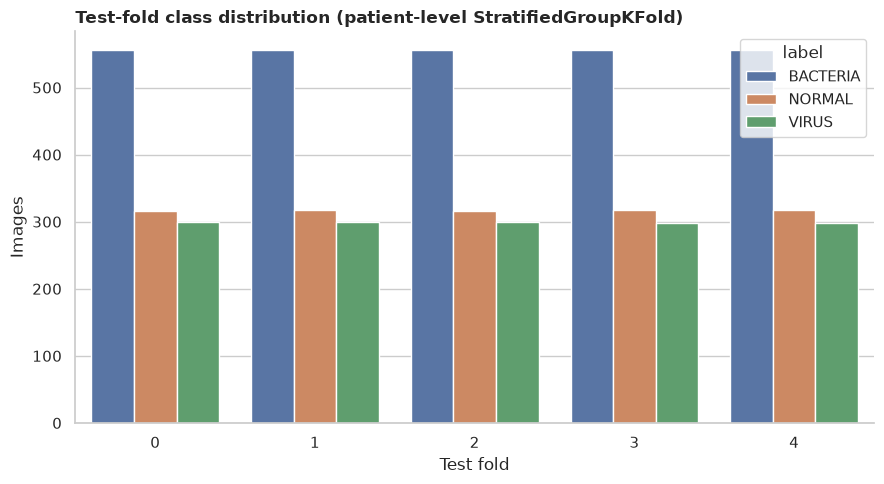

In [10]:
# ============================================================
# 9. Class distribution per fold (test portion)
# ============================================================
plot_df = (df.groupby(["test_fold", "label"]).size().rename("Images").reset_index())
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=plot_df, x="test_fold", y="Images", hue="label", ax=ax)
ax.set_title("Test-fold class distribution (patient-level StratifiedGroupKFold)", loc="left", fontweight="bold")
ax.set_xlabel("Test fold"); ax.set_ylabel("Images")
sns.despine()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fold_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()